### Predicting for the House Price Challenge



In [1]:
import pandas as pd
from sklearn.linear_model import LinearRegression

In [2]:
df = pd.read_csv('train.csv')

In [3]:
X = df[['OverallQual']]
y = df['SalePrice']

In [4]:
model = LinearRegression().fit(X, y)

In [5]:
test = pd.read_csv('test.csv')

In [7]:
preds = model.predict(test[['OverallQual']])

In [16]:
pdf = pd.DataFrame(preds, columns = ['SalePrice'])

In [17]:
pdf['Id'] = test.index

In [19]:
pdf.to_csv('preds.csv', index = False)

In [20]:
pdf.head()

,SalePrice,Id
0,84069.869089,0
1,222803.492715,1
2,130314.410297,2
3,222803.492715,3
4,130314.410297,4


In [22]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


### Missing Values and Imputation

In [29]:
df.columns[df.isna().sum() > 0]

Index(['LotFrontage', 'Alley', 'MasVnrType', 'MasVnrArea', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
       'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish',
       'GarageQual', 'GarageCond', 'PoolQC', 'Fence', 'MiscFeature'],
      dtype='object')

In [32]:
df[df.columns[df.isna().sum() > 0]].isna().sum()/len(df)

,0
LotFrontage,0.175000
Alley,0.937500
MasVnrType,0.597500
MasVnrArea,0.005000
BsmtQual,0.026667
BsmtCond,0.026667
BsmtExposure,0.027500
BsmtFinType1,0.026667
BsmtFinType2,0.027500
FireplaceQu,0.470000


### Impute Missing Values

- Fill numeric values with mean
- Fill categorical values with most frequent value

In [33]:
missing = df[df.columns[df.isna().sum() > 0]]

In [36]:
nums_missing = missing.select_dtypes(['float', 'int']).columns.tolist()

In [37]:
cat_missing = missing.select_dtypes('object').columns.tolist()

In [38]:
from sklearn.impute import SimpleImputer

In [39]:
from sklearn.compose import make_column_transformer

In [40]:
imputer = make_column_transformer((SimpleImputer(), nums_missing),
                                  (SimpleImputer(strategy = "most_frequent"), cat_missing),
                                  remainder = 'passthrough',
                                  verbose_feature_names_out=False)

In [41]:
imputer.fit_transform(df)

array([[65.0, 196.0, 2003.0, ..., 'WD', 'Normal', 208500],
       [80.0, 0.0, 1976.0, ..., 'WD', 'Normal', 181500],
       [68.0, 162.0, 2001.0, ..., 'WD', 'Normal', 223500],
       ...,
       [65.0, 0.0, 1916.0, ..., 'ConLw', 'Normal', 144000],
       [70.0, 0.0, 2001.0, ..., 'WD', 'Normal', 178000],
       [75.0, 51.0, 1974.0, ..., 'WD', 'Normal', 148000]], dtype=object)

### Ordinal Encoding

Categorical columns that are ordered can be encoded with the `OrdinalEncoder`.

In [42]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [47]:
df['KitchenQual'].value_counts()

,count
KitchenQual,
TA,602
Gd,482
Ex,81
Fa,35


In [49]:
df['KitchenQual'].value_counts().index.tolist()

['TA', 'Gd', 'Ex', 'Fa']

Create a list of categories for the encoder.

In [48]:
from sklearn.preprocessing import OrdinalEncoder

In [204]:
vals = [['Po', 'Fa', 'Gd', 'TA', 'Ex']]

In [205]:
oe = OrdinalEncoder(categories=vals)

In [253]:
oe.fit_transform(df[['KitchenQual']])

array([[2.],
       [3.],
       [2.],
       ...,
       [3.],
       [2.],
       [3.]])

In [254]:
oe.categories_

[array(['Po', 'Fa', 'Gd', 'TA', 'Ex'], dtype=object)]

In [255]:
oe.transform(df[['KitchenQual']])

array([[2.],
       [3.],
       [2.],
       ...,
       [3.],
       [2.],
       [3.]])

In [257]:
df['KitchenQual'].head()

,KitchenQual
0,Gd
1,TA
2,Gd
3,Gd
4,Gd


### OneHotEncoder

In [210]:
from sklearn.preprocessing import OneHotEncoder

In [211]:
ord_cols = df[[col for col in df[cat_missing].columns if 'Qu' in col]].select_dtypes('object').columns.tolist()

In [212]:
ord_cols += ['BsmtCond', 'GarageCond', 'KitchenQual']

In [213]:
ohe_cols = df[[col for col in df[cat_missing].select_dtypes('object').columns if col not in ord_cols]].columns.tolist()

In [214]:
ohe_cols

['Alley',
 'MasVnrType',
 'BsmtExposure',
 'BsmtFinType1',
 'BsmtFinType2',
 'GarageType',
 'GarageFinish',
 'PoolQC',
 'Fence',
 'MiscFeature']

### Pipeline

In [216]:
from sklearn.pipeline import Pipeline

In [217]:
vals*len(ord_cols)

[['Po', 'Fa', 'Gd', 'TA', 'Ex'],
 ['Po', 'Fa', 'Gd', 'TA', 'Ex'],
 ['Po', 'Fa', 'Gd', 'TA', 'Ex'],
 ['Po', 'Fa', 'Gd', 'TA', 'Ex'],
 ['Po', 'Fa', 'Gd', 'TA', 'Ex'],
 ['Po', 'Fa', 'Gd', 'TA', 'Ex']]

In [218]:
imputer = make_column_transformer((SimpleImputer(), nums_missing),
                                  (SimpleImputer(strategy = "most_frequent"), cat_missing),
                                  (OrdinalEncoder(categories = vals*len(ord_cols)), ord_cols),
                                  (OneHotEncoder(drop = 'first'), ohe_cols),
                                  remainder = 'passthrough',
                                  verbose_feature_names_out=False)

In [219]:
cols = nums_missing + cat_missing + ['KitchenQual', 'OverallQual']

In [224]:
X = df[cols]
y = df['SalePrice']

In [225]:
cols

['LotFrontage',
 'MasVnrArea',
 'GarageYrBlt',
 'Alley',
 'MasVnrType',
 'BsmtQual',
 'BsmtCond',
 'BsmtExposure',
 'BsmtFinType1',
 'BsmtFinType2',
 'FireplaceQu',
 'GarageType',
 'GarageFinish',
 'GarageQual',
 'GarageCond',
 'PoolQC',
 'Fence',
 'MiscFeature',
 'KitchenQual',
 'OverallQual']

In [227]:
pipe = Pipeline([('fill_and_order', imputer), ('model', LinearRegression())])

In [229]:
pipe.fit(X, y)

ValueError: Found unknown categories [nan] in column 0 during fit

### Separate the encoding and onehot transformations into pipelines

In [240]:
cat_imputer = SimpleImputer(strategy = 'most_frequent')
ord_imputer = SimpleImputer(strategy = 'most_frequent')
ohe = OneHotEncoder(drop = 'first', handle_unknown='ignore')
ord = OrdinalEncoder(categories = vals*len(ord_cols))

ohe_pipe = Pipeline([('impute', cat_imputer), ('ohe', ohe)])
ord_pipe = Pipeline([('impute', ord_imputer), ('ord', ord)])
transformer = make_column_transformer((ohe_pipe, ohe_cols),
                                      (ord_pipe, ord_cols),
                                      (SimpleImputer(), nums_missing),
                                      remainder = 'passthrough')

In [241]:
transformer.fit_transform(X)









array([[0.000e+00, 1.000e+00, 0.000e+00, ..., 1.960e+02, 2.003e+03,
        7.000e+00],
       [0.000e+00, 1.000e+00, 0.000e+00, ..., 0.000e+00, 1.976e+03,
        6.000e+00],
       [0.000e+00, 1.000e+00, 0.000e+00, ..., 1.620e+02, 2.001e+03,
        7.000e+00],
       ...,
       [0.000e+00, 1.000e+00, 0.000e+00, ..., 0.000e+00, 1.916e+03,
        7.000e+00],
       [0.000e+00, 1.000e+00, 0.000e+00, ..., 0.000e+00, 2.001e+03,
        7.000e+00],
       [0.000e+00, 1.000e+00, 0.000e+00, ..., 5.100e+01, 1.974e+03,
        4.000e+00]])

### Pipeline with Model

In [242]:
model_pipeline = Pipeline([('transform', transformer), ('model', LinearRegression())])

In [243]:
model_pipeline.fit(X, y)

/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('transform',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('pipeline-1',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('ohe',
                                                                   OneHotEncoder(drop='first',
                                                                                 handle_unknown='ignore'))]),
                                                  ['Alley', 'MasVnrType',
                                                   'BsmtExposure',
                                                   'BsmtFinType1',
                                                   'BsmtFinType2', 'GarageType',
                                                   'GarageFinish', 'PoolQC',
                                                   'Fence', 'MiscFeatu...
                                                                                               'Fa',
                                                                                               'Gd',
                                                                                               'TA',
                                                                                               'Ex'],
                                                                                              ['Po',
                                                                                               'Fa',
                                                                                               'Gd',
                                                                                               'TA',
                                                                                               'Ex'],
                                                                                              ['Po',
                                                                                               'Fa',
                                                                                               'Gd',
                                                                                               'TA',
                                                                                               'Ex'],
                                                                                              ['Po',
                                                                                               'Fa',
                                                                                               'Gd',
                                                                                               'TA',
                                                                                               'Ex'],
                                                                                              ['Po',
                                                                                               'Fa',
                                                                                               'Gd',
                                                                                               'TA',
                                                                                               'Ex'],
                                                                                              ['Po',
                                                                                               'Fa',
                                                                                               'Gd',
                                                                                               'TA',
                                                                                               'Ex']]))]),
 

In [244]:
test.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1201,20,RL,71.0,9353,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,NaN,Shed,0,7,2006,Oth,Abnorml
1,1202,60,RL,80.0,10400,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,3,2009,WD,Normal
2,1203,50,RM,50.0,6000,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,5,2009,WD,Normal
3,1204,20,RL,75.0,9750,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,10,2009,WD,Normal
4,1205,20,RL,78.0,10140,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,MnPrv,NaN,0,7,2006,WD,Normal


In [245]:
X_test = test[X.columns.tolist()]

In [246]:
model_pipeline.predict(X_test)

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [9] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


array([ 89967.84325401, 191449.95790767,  98910.13647032, 200175.40855547,
       133737.08267683, 235631.58341472,  94581.80216216, 176994.01689567,
       128100.44791981, 312807.38429777, 145172.21618938, 279890.75585541,
        76792.02259745, 110222.34703273, 132290.21357009, 146386.8095358 ,
       171602.06172337, 267220.89091127,  96842.49459045, 139975.1744838 ,
       123384.97790418, 129605.65264765, 181028.36484932, 144619.06891706,
       207655.70815735, 162362.67649869, 223756.99191238, 152564.62360215,
       343801.99792912, 118164.65632477, 138877.09292911, 133119.99307664,
       100394.60754703, 138620.33423905, 117634.41702617, 130788.05670808,
       205606.85142353, 197627.36640745, 148482.88181144, 243649.05390657,
       210923.36992224, 210982.7803612 , 245390.50364587, 400641.02695699,
       195480.58358575, 198344.9267522 , 181465.63042223, 193032.69087957,
       145918.40289442, 124239.8372329 , 238889.72099564, 208204.70391916,
       121290.51982598, 2

<Axes: >

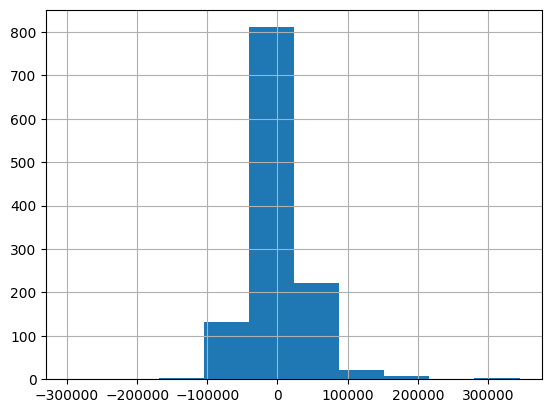

In [252]:
(y - model_pipeline.predict(X)).hist()